# Credit Score Classification — Poor / Standard / Good

notebook นี้สร้างโมเดลทำนาย **เครดิตสกอร์ของลูกค้า 3 ระดับ** จากข้อมูลการเงิน เช่น รายได้ หนี้ จำนวนบัตรเครดิต และพฤติกรรมการจ่ายเงิน

**ขั้นตอนหลัก:** โหลดข้อมูล → ทำความสะอาด → สำรวจข้อมูล → แบ่ง train/valid → จัดการ outlier → ปรับสเกล + แปลงหมวดหมู่ → ลดมิติด้วย PCA → เทรนหลายโมเดลแล้วเทียบกัน → ทำนาย `test.csv`

**ไฟล์ที่ต้องมีในโฟลเดอร์เดียวกับ notebook:** `train.csv` (มี `Credit_Score`) และ `test.csv` (ไม่มี `Credit_Score`)


## Step 1 — Import ไลบรารีและตั้งค่า
- `pandas`, `numpy` จัดการข้อมูล
- `matplotlib`, `seaborn` วาดกราฟ
- `sklearn` สำหรับ preprocessing, PCA, โมเดล และวัดผล

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

TRAIN_PATH = Path("/Users/rosarinmanor/Documents/financial-data-analysis/financial-data-analytics/peetorohan-financial/week2/train.csv")
TEST_PATH = Path("/Users/rosarinmanor/Documents/financial-data-analysis/financial-data-analytics/peetorohan-financial/week2/test.csv")

RANDOM_STATE = 42

In [2]:
print(TRAIN_PATH.exists(), TEST_PATH.exists())

True True


## Step 2 — โหลดข้อมูลและดูภาพรวม
`low_memory=False` ป้องกันคำเตือน mixed types เพราะบางคอลัมน์ตัวเลขมีข้อความปนอยู่

In [3]:
train_raw = pd.read_csv(TRAIN_PATH, low_memory=False)
test_raw = pd.read_csv(TEST_PATH, low_memory=False)

print("train:", train_raw.shape, "| ลูกค้า:", train_raw["Customer_ID"].nunique(), "| เดือน:", train_raw["Month"].nunique())
print("test :", test_raw.shape, "| ลูกค้า:", test_raw["Customer_ID"].nunique(), "| เดือน:", test_raw["Month"].nunique())
print("test มี Credit_Score ไหม:", "Credit_Score" in test_raw.columns)
train_raw.head()

train: (100000, 28) | ลูกค้า: 12500 | เดือน: 8
test : (50000, 27) | ลูกค้า: 12500 | เดือน: 4
test มี Credit_Score ไหม: False


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


In [4]:
train_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  object 
 13  Type_of_Loan              88592 non-null   ob

## Step 3 — ตรวจ "ขยะ" ในข้อมูล
ข้อมูลชุดนี้ถูกใส่ค่าเสียไว้ตั้งใจ ซึ่ง `isnull()` มองไม่เห็นทั้งหมด:
- สัญลักษณ์แทนค่าว่าง เช่น `_______`, `_`, `NM`, `!@9#%8`
- ตัวเลขที่มี `_` ติด เช่น `23_`, `__10000__`
- ค่าที่เป็นไปไม่ได้ เช่น อายุ `-500`

In [5]:
placeholders = {
    "Occupation": "_______",
    "Credit_Mix": "_",
    "Payment_of_Min_Amount": "NM",
    "Payment_Behaviour": "!@9#%8",
}
text_num_cols = ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment",
                 "Changed_Credit_Limit", "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance"]

print("สัญลักษณ์แทนค่าว่าง (train vs test):")
display(pd.DataFrame([{
    "column": c,
    "placeholder": p,
    "train_count": int((train_raw[c] == p).sum()),
    "test_count": int((test_raw[c] == p).sum())
} for c, p in placeholders.items()]))

print("\nจำนวนค่าที่มี '_' ปนในคอลัมน์ตัวเลข (train):")
print({c: int(train_raw[c].astype(str).str.contains("_").sum()) for c in text_num_cols})

print("\nค่าว่างจริง (NaN) ใน train:")
display(train_raw.isnull().sum()[lambda s: s > 0].to_frame("missing"))

สัญลักษณ์แทนค่าว่าง (train vs test):


,column,placeholder,train_count,test_count
0,Occupation,_______,7062,3438
1,Credit_Mix,_,20195,9805
2,Payment_of_Min_Amount,NM,12007,5993
3,Payment_Behaviour,!@9#%8,7600,3800



จำนวนค่าที่มี '_' ปนในคอลัมน์ตัวเลข (train):
{'Age': 4939, 'Annual_Income': 6980, 'Num_of_Loan': 4785, 'Num_of_Delayed_Payment': 2744, 'Changed_Credit_Limit': 2091, 'Outstanding_Debt': 1009, 'Amount_invested_monthly': 4305, 'Monthly_Balance': 9}

ค่าว่างจริง (NaN) ใน train:


,missing
Name,9985
Monthly_Inhand_Salary,15002
Type_of_Loan,11408
Num_of_Delayed_Payment,7002
Num_Credit_Inquiries,1965
Credit_History_Age,9030
Amount_invested_monthly,4479
Monthly_Balance,1200


## Step 4 — Data Cleaning & Feature Engineering

เชื่อมโยงข้อมูลประวัติรายเดือนของลูกค้ากลุ่มเดิมต่อเนื่องตั้งแต่เดือนมกราคม–ธันวาคม (`train` → `test`) เพื่อกู้คืนค่าว่างและสร้างฟีเจอร์เชิงพฤติกรรม:

1. **Sanitization:** แทนที่สัญลักษณ์ขยะ (`_______`, `_`, `NM`, `!@9#%8`) และค่านอกช่วงที่เป็นไปไม่ได้ด้วย `NaN` พร้อมลบอักขระ `_` และแปลงชนิดข้อมูลตัวเลข
2. **Feature Extraction:** แปลงอายุเครดิต (`Credit_History_Age`) เป็นจำนวนเดือน และนับจำนวนประเภทสินเชื่อจาก `Type_of_Loan` (`Num_Loan_Types`)
3. **Longitudinal Imputation:** เรียงข้อมูลตาม `Customer_ID` และลำดับเดือน (`1 → 12`) แล้วเติมค่าว่างจากเดือนก่อนหน้า (`ffill`) และค่ากลางรายบุคคล (ดึงประวัติจาก `train` มาเติมให้ `test` เพื่อป้องกันข้อมูลขาดช่วง)
4. **Lag Features:** สร้างตัวแปรพฤติกรรมจากเดือนก่อนหน้า (`Prev_Outstanding_Debt`, `Prev_Delay_from_due_date`, `Prev_Credit_Utilization_Ratio`) เพื่อจับแนวโน้มการเปลี่ยนแปลงทางการเงิน
5. **Column Selection:** คัดกรองเฉพาะฟีเจอร์ที่พร้อมสำหรับการเทรนโมเดลและตัดคอลัมน์ระบุตัวตนออก

In [6]:
MONTHS = {m: i for i, m in enumerate(
    ["January", "February", "March", "April", "May", "June",
     "July", "August", "September", "October", "November", "December"], start=1)}

RAW_NUM_COLS = ["Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card",
                "Interest_Rate", "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
                "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt",
                "Credit_Utilization_Ratio", "Total_EMI_per_month", "Amount_invested_monthly", "Monthly_Balance"]

LAG_COLS = ["Outstanding_Debt", "Delay_from_due_date", "Credit_Utilization_Ratio"]
NUM_COLS = RAW_NUM_COLS + ["Credit_History_Months", "Num_Loan_Types"] + [f"Prev_{c}" for c in LAG_COLS]
CAT_COLS = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]

VALID_RANGE = {
    "Age": (14, 100), "Annual_Income": (0, 500_000),
    "Num_Bank_Accounts": (0, 20), "Num_Credit_Card": (0, 20),
    "Interest_Rate": (1, 40), "Num_of_Loan": (0, 20),
    "Num_of_Delayed_Payment": (0, 30), "Num_Credit_Inquiries": (0, 100),
    "Outstanding_Debt": (0, 5_000), "Total_EMI_per_month": (0, 2_000),
    "Amount_invested_monthly": (0, 2_000),
}

def to_num(s):
    s = s.astype(str).str.replace("_", "", regex=False)
    s = s.replace({"": np.nan, "nan": np.nan, "None": np.nan})
    return pd.to_numeric(s, errors="coerce")

def parse_history(s):
    ex = s.astype("string").str.extract(r"(\d+)\s+Years?\s+and\s+(\d+)\s+Months?").astype(float)
    return ex[0] * 12 + ex[1]

def _mode(s):
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan

def clean_credit_data(df, ref_train=None):
    if ref_train is not None:
        tr, te = ref_train.copy(), df.copy()
        tr["_is_target"], te["_is_target"] = False, True
        d = pd.concat([tr, te], ignore_index=True)
    else:
        d = df.copy()
        d["_is_target"] = True

    # 1) สัญลักษณ์ขยะ -> NaN
    for col, ph in placeholders.items():
        d[col] = d[col].replace(ph, np.nan)

    # 2) ตัวเลขที่เป็นข้อความ -> float
    for c in RAW_NUM_COLS:
        d[c] = to_num(d[c])

    # 3) อายุเครดิตเป็นเดือน และเตรียมประเภทสินเชื่อ
    d["Credit_History_Months"] = parse_history(d["Credit_History_Age"])
    d["Type_of_Loan"] = d["Type_of_Loan"].replace(["Not Specified", "nan", "None"], np.nan)

    # 4) ค่าที่เป็นไปไม่ได้ -> NaN
    for c, (lo, hi) in VALID_RANGE.items():
        d.loc[(d[c] < lo) | (d[c] > hi), c] = np.nan
    d.loc[d["Monthly_Balance"].abs() > 1e8, "Monthly_Balance"] = np.nan

    # 5) เรียงตามลูกค้า/เดือน (1 -> 12) แล้วเติมค่าที่หาย
    d["Month_Num"] = d["Month"].map(MONTHS)
    d = d.sort_values(["Customer_ID", "Month_Num"]).reset_index(drop=True)

    d["Credit_History_Months"] = d.groupby("Customer_ID")["Credit_History_Months"].transform(
        lambda s: s.interpolate(limit_direction="both"))

    d["Type_of_Loan"] = d.groupby("Customer_ID")["Type_of_Loan"].ffill().bfill()
    d["Num_Loan_Types"] = d["Type_of_Loan"].fillna("").apply(lambda x: 0 if x == "" else len(x.split(",")))

    for c in RAW_NUM_COLS + ["Credit_History_Months"]:
        d[c] = d.groupby("Customer_ID")[c].ffill()
        d[c] = d[c].fillna(d.groupby("Customer_ID")[c].transform("median"))
        d[c] = d[c].fillna(d[c].median())

    for c in CAT_COLS:
        d[c] = d.groupby("Customer_ID")[c].ffill()
        d[c] = d[c].fillna(d.groupby("Customer_ID")[c].transform(_mode))
        d[c] = d[c].fillna(d[c].mode().iloc[0])

    # 6) สร้างฟีเจอร์จากเดือนก่อนหน้า (Lag Features)
    for col in LAG_COLS:
        d[f"Prev_{col}"] = d.groupby("Customer_ID")[col].shift(1).bfill()

    # 7) ดึงเฉพาะส่วนเป้าหมายกลับออกไป และตัดคอลัมน์ที่ไม่ใช้
    d = d[d["_is_target"]].reset_index(drop=True)
    keep = ["ID", "Customer_ID", "Month", "Month_Num"] + NUM_COLS + CAT_COLS
    if ref_train is None and "Credit_Score" in d.columns:
        keep.append("Credit_Score")
    return d[keep]

In [7]:
train_df = clean_credit_data(train_raw)
test_df = clean_credit_data(test_raw, ref_train=train_raw)

print("train หลังล้าง:", train_df.shape, "| ค่าว่างที่เหลือ:", int(train_df.isnull().sum().sum()))
print("test  หลังล้าง:", test_df.shape, "| ค่าว่างที่เหลือ:", int(test_df.isnull().sum().sum()))
train_df.head()

train หลังล้าง: (100000, 30) | ค่าว่างที่เหลือ: 0
test  หลังล้าง: (50000, 29) | ค่าว่างที่เหลือ: 0


,ID,Customer_ID,Month,Month_Num,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Credit_History_Months,Num_Loan_Types,Prev_Outstanding_Debt,Prev_Delay_from_due_date,Prev_Credit_Utilization_Ratio,Occupation,Credit_Mix,Payment_of_Min_Amount,Payment_Behaviour,Credit_Score
0,0x1628a,CUS_0x1000,January,1,17.0,30625.94,2706.161667,6.0,5.0,27.0,2.0,62,25.0,1.63,10.0,1562.91,26.612093,42.94109,244.750283,252.924793,122.0,2,1562.91,62.0,26.612093,Lawyer,Bad,Yes,Low_spent_Large_value_payments,Standard
1,0x1628b,CUS_0x1000,February,2,17.0,30625.94,2706.161667,6.0,5.0,27.0,2.0,62,23.0,1.63,11.0,1562.91,29.439759,42.94109,176.132567,311.542510,123.0,2,1562.91,62.0,26.612093,Lawyer,Bad,Yes,High_spent_Small_value_payments,Poor
2,0x1628c,CUS_0x1000,March,3,17.0,30625.94,2706.161667,6.0,5.0,27.0,2.0,62,28.0,1.63,11.0,1562.91,38.285928,42.94109,109.056519,368.618557,124.0,2,1562.91,62.0,29.439759,Lawyer,Bad,Yes,High_spent_Medium_value_payments,Poor
3,0x1628d,CUS_0x1000,April,4,17.0,30625.94,2706.161667,6.0,5.0,27.0,2.0,64,25.0,1.63,11.0,1562.91,32.843081,42.94109,87.909909,419.765167,125.0,2,1562.91,62.0,38.285928,Lawyer,Bad,Yes,High_spent_Medium_value_payments,Poor
4,0x1628e,CUS_0x1000,May,5,17.0,30625.94,2706.161667,6.0,5.0,27.0,2.0,67,25.0,2.63,11.0,1562.91,32.330508,42.94109,191.834767,305.840309,126.0,2,1562.91,64.0,32.843081,Lawyer,Bad,Yes,Low_spent_Large_value_payments,Poor


### ตรวจผลก่อน/หลังล้าง
boxplot แถวบนคือก่อนล้าง (ค่าขยะทำให้กราฟยืดผิดปกติ) แถวล่างคือหลังล้าง

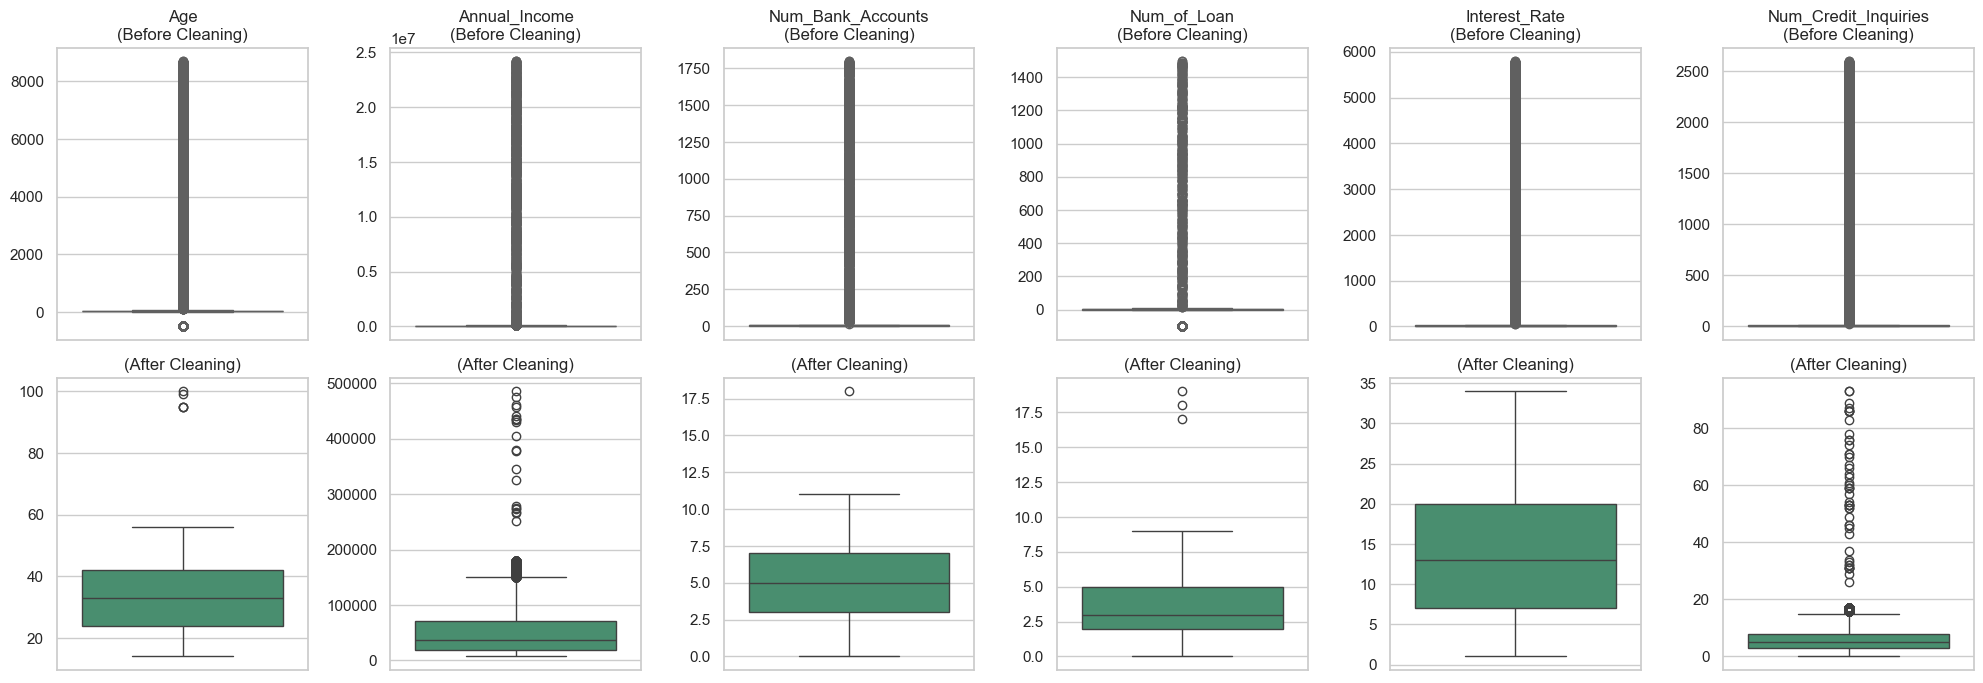

In [8]:
cmp_cols = ["Age", "Annual_Income", "Num_Bank_Accounts", "Num_of_Loan", "Interest_Rate", "Num_Credit_Inquiries"]
fig, axes = plt.subplots(2, len(cmp_cols), figsize=(20, 7))
for i, c in enumerate(cmp_cols):
    sns.boxplot(y=to_num(train_raw[c]), ax=axes[0, i], color="#e07a5f")
    axes[0, i].set_title(f"{c}\n(Before Cleaning)")
    sns.boxplot(y=train_df[c], ax=axes[1, i], color="#3d9970")
    axes[1, i].set_title("(After Cleaning)")
    for r in (0, 1):
        axes[r, i].set_ylabel("")
plt.tight_layout(); plt.show()

## Step 5 — สำรวจข้อมูล (EDA)
ดูสัดส่วนของ `Credit_Score`, การกระจายของตัวแปรตัวเลข และความสัมพันธ์กับเครดิตสกอร์

Credit_Score
Poor        0.290
Standard    0.532
Good        0.178


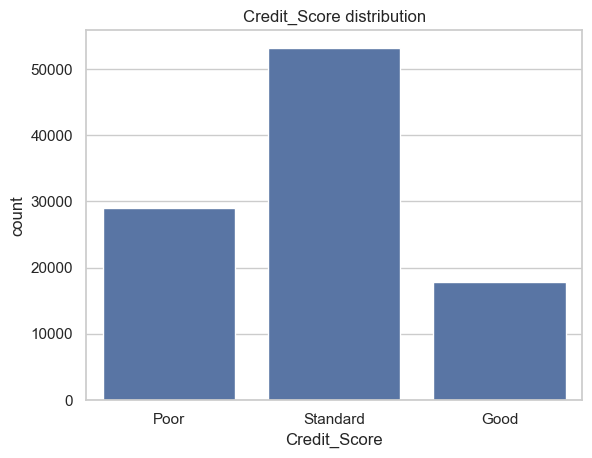

In [31]:
# สัดส่วนเครดิตสกอร์ (ถ้าคลาสไม่สมดุล accuracy อย่างเดียวอาจหลอกตา จึงดู macro F1 ด้วยภายหลัง)
order = ["Poor", "Standard", "Good"]
print(train_df["Credit_Score"].value_counts(normalize=True).reindex(order).round(3).to_string())
sns.countplot(data=train_df, x="Credit_Score", order=order)
plt.title("Credit_Score distribution"); plt.show()

,count,mean,std,min,25%,50%,75%,max
Age,100000.000000,33.313360,10.774107,14.000000,24.000000,33.000000,42.000000,100.000000
Annual_Income,100000.000000,50571.981080,38586.732956,7005.930000,19344.270000,37006.600000,71691.735000,485755.000000
Monthly_Inhand_Salary,100000.000000,4198.587581,3187.321199,303.645417,1626.761667,3096.378333,5961.745000,15204.633333
Num_Bank_Accounts,100000.000000,5.368940,2.593586,0.000000,3.000000,5.000000,7.000000,18.000000
Num_Credit_Card,100000.000000,5.534430,2.069381,0.000000,4.000000,5.000000,7.000000,20.000000
Interest_Rate,100000.000000,14.532080,8.741330,1.000000,7.000000,13.000000,20.000000,34.000000
Num_of_Loan,100000.000000,3.533380,2.447604,0.000000,2.000000,3.000000,5.000000,19.000000
Delay_from_due_date,100000.000000,21.068780,14.860104,-5.000000,10.000000,18.000000,28.000000,67.000000
Num_of_Delayed_Payment,100000.000000,13.333840,6.270035,0.000000,9.000000,14.000000,18.000000,28.000000
Changed_Credit_Limit,100000.000000,10.389403,6.789306,-6.490000,5.330000,9.400000,14.860000,36.970000


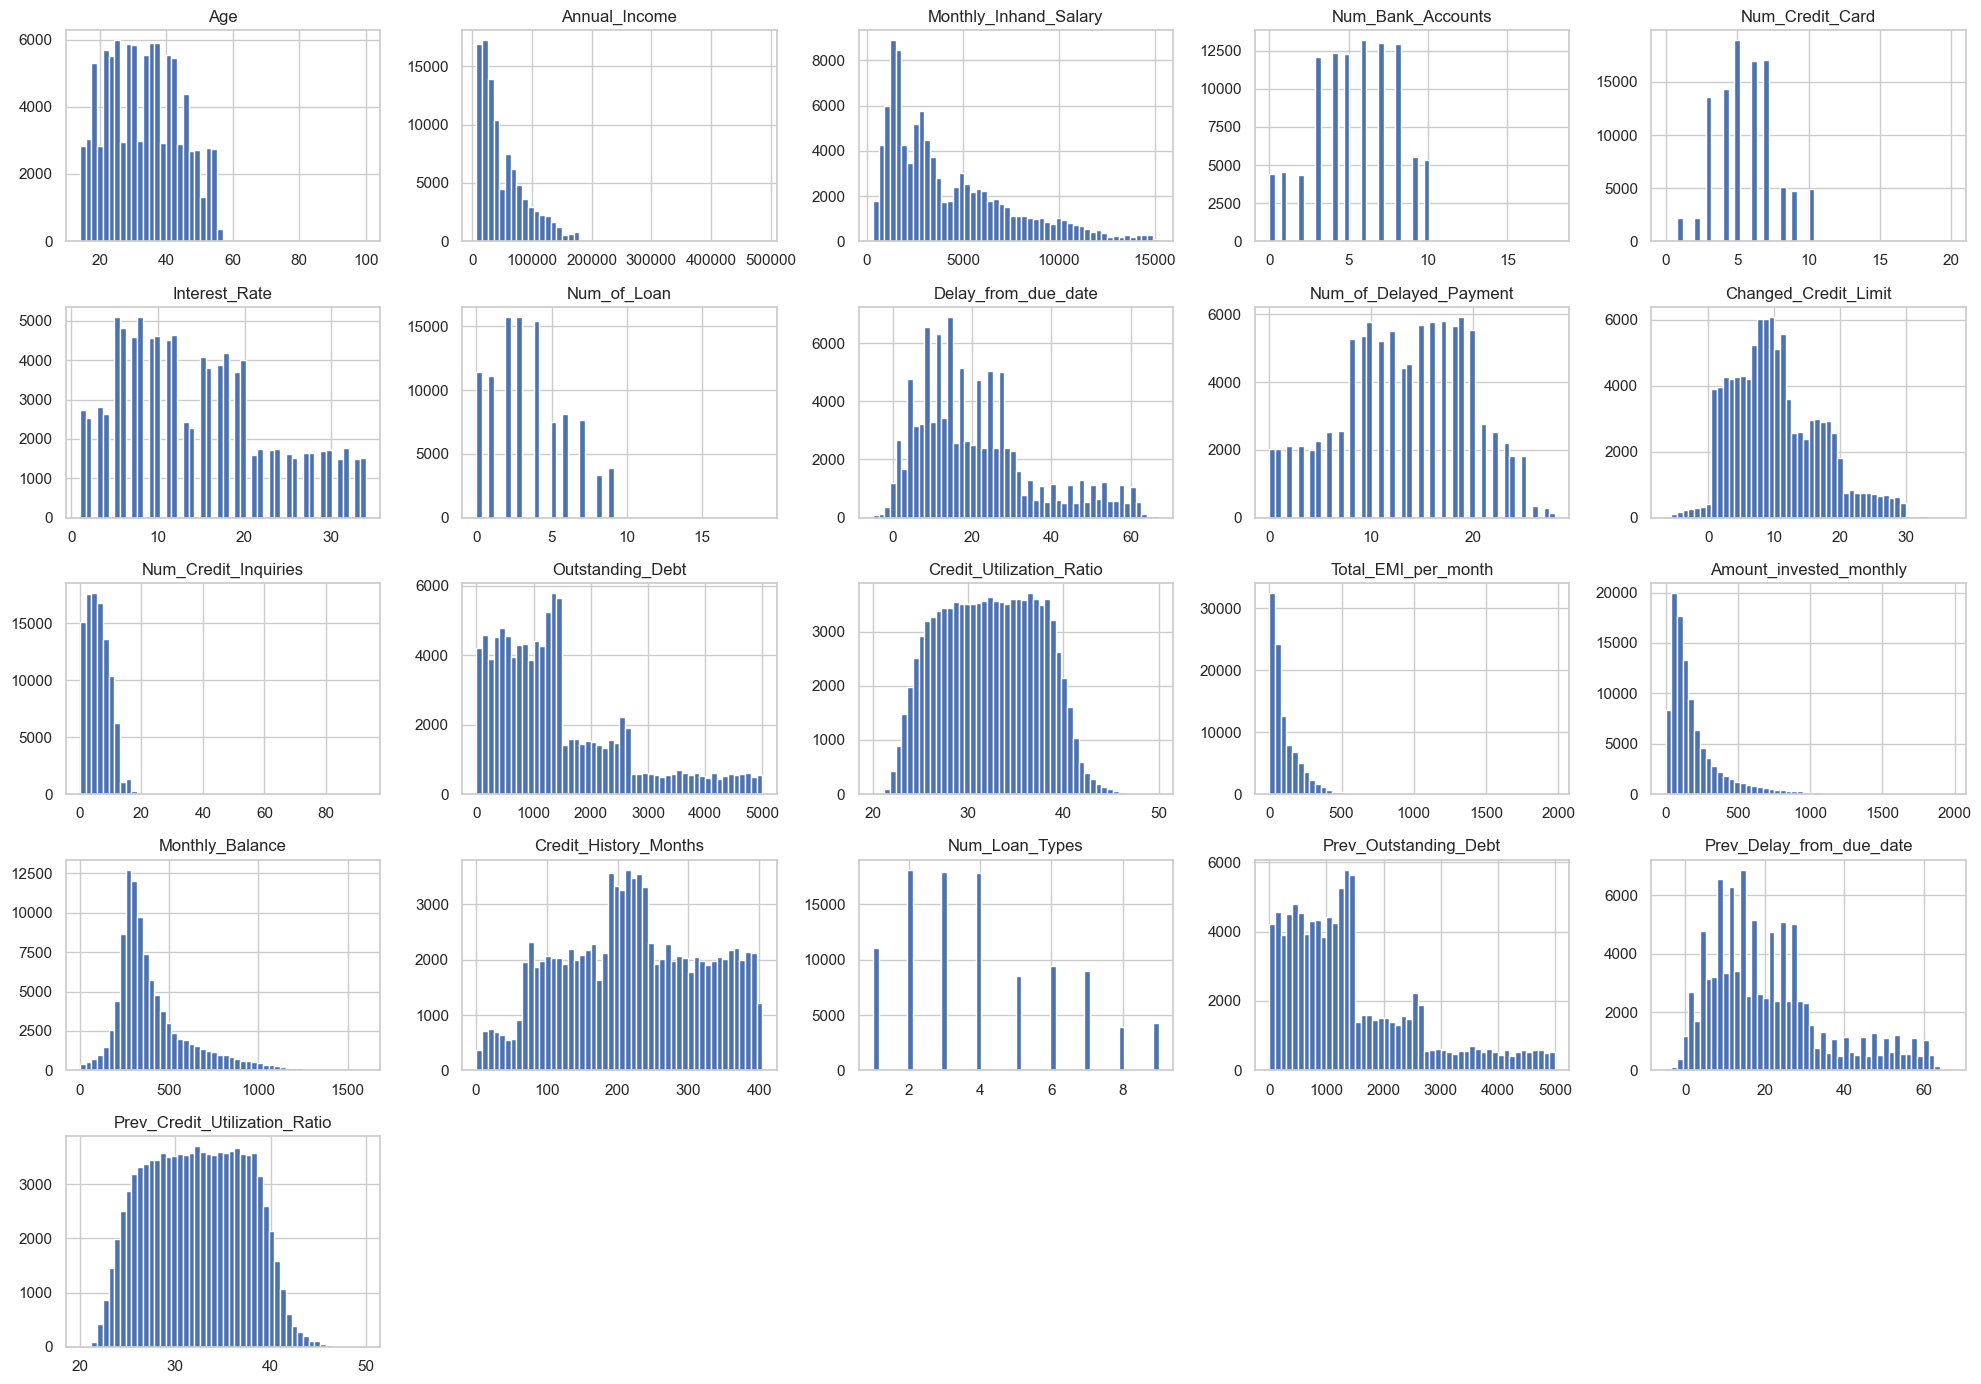

In [32]:
display(train_df[NUM_COLS].describe().T.style.background_gradient(cmap="Blues"))
train_df[NUM_COLS].hist(bins=50, figsize=(20, 14))
plt.tight_layout(); plt.show()

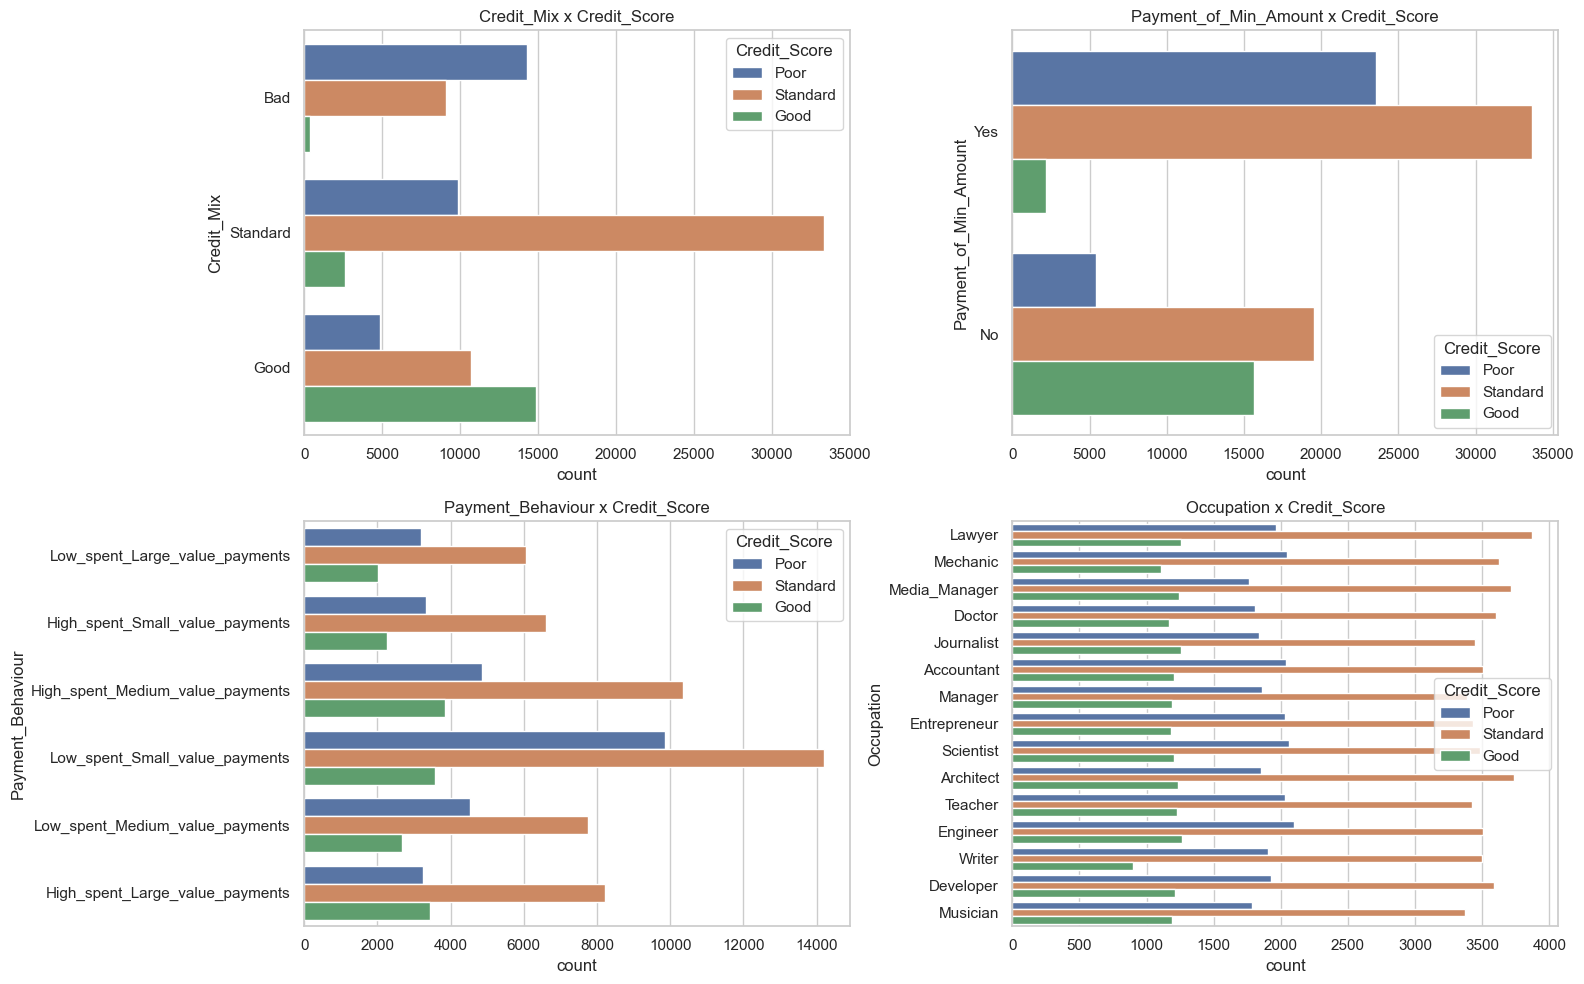

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.ravel(), ["Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour", "Occupation"]):
    sns.countplot(data=train_df, y=col, hue="Credit_Score", hue_order=order, ax=ax)
    ax.set_title(f"{col} x Credit_Score")
plt.tight_layout(); plt.show()

,Annual_Income,Outstanding_Debt,Interest_Rate,Num_of_Delayed_Payment,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Credit_History_Months
Credit_Score,,,,,,,,
Poor,40622.7,2081.5,20.2,15.8,29.7,8.2,32.0,170.0
Standard,51075.9,1278.4,13.8,13.6,19.7,5.3,32.3,227.8
Good,65252.0,801.3,7.7,8.6,10.9,3.3,32.7,284.8


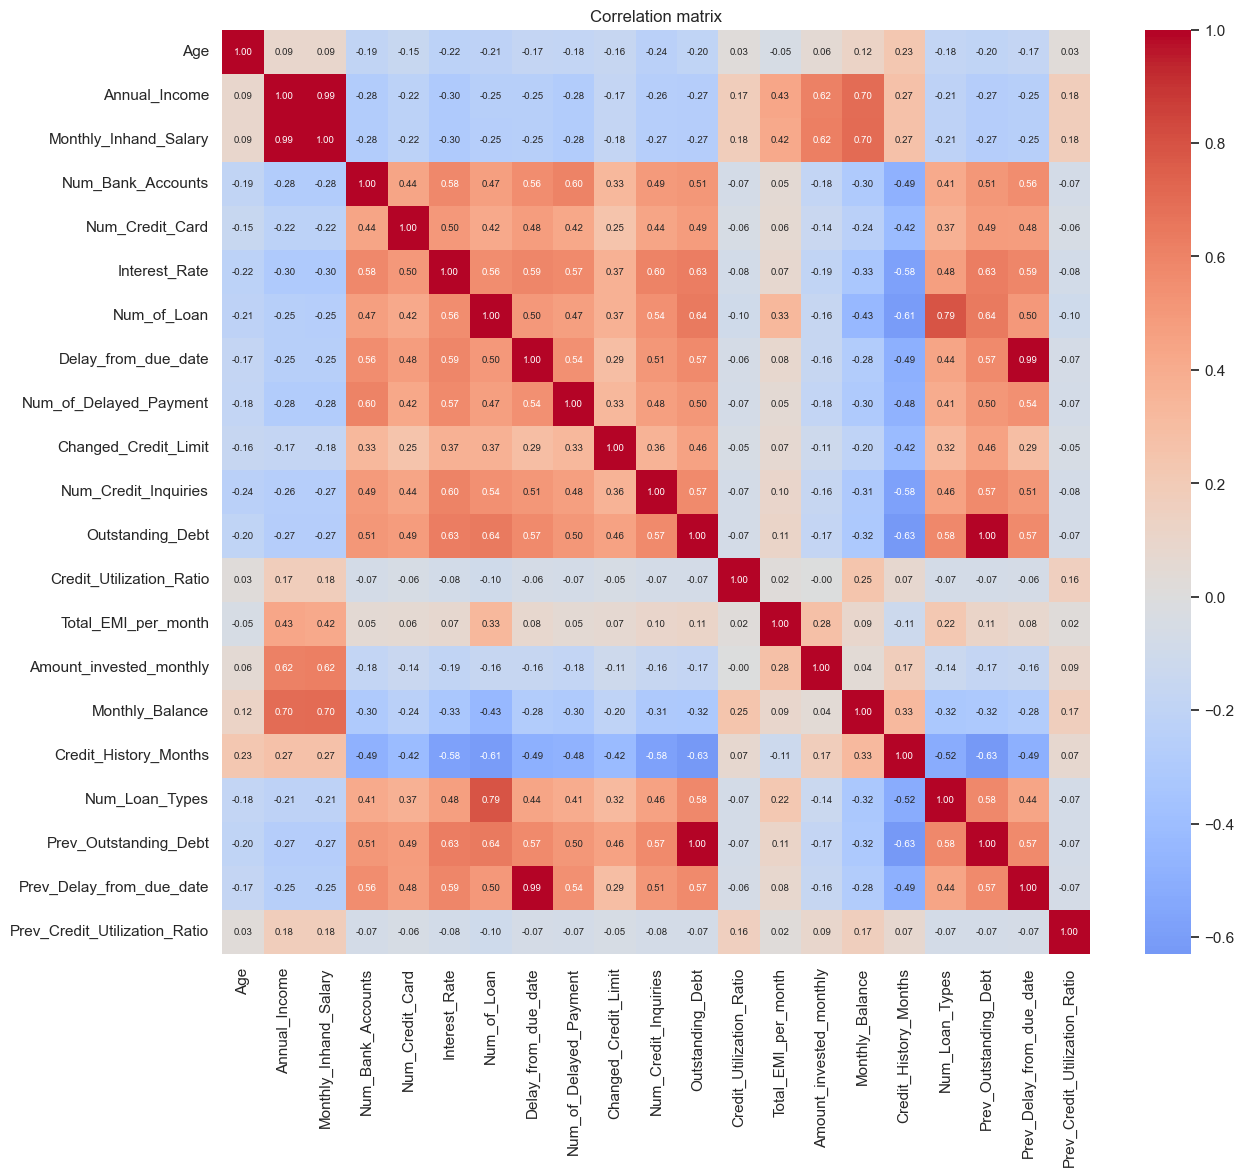

In [12]:
# ตัวแปรตัวเลขเฉลี่ยตามเครดิตสกอร์ (ดูว่าฟีเจอร์ไหนแยกกลุ่มได้ชัด)
cols_show = ["Annual_Income", "Outstanding_Debt", "Interest_Rate", "Num_of_Delayed_Payment",
             "Delay_from_due_date", "Num_Credit_Inquiries", "Credit_Utilization_Ratio", "Credit_History_Months"]
display(train_df.groupby("Credit_Score")[cols_show].mean().reindex(order).round(1))

plt.figure(figsize=(14, 12))
sns.heatmap(train_df[NUM_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix"); plt.show()

## Step 6 — แบ่งข้อมูล train / valid (ตามช่วงเวลา)
เนื่องจากข้อสอบจริง (`test.csv`) คือการทำนายเดือนอนาคต (ก.ย.–ธ.ค.) ของลูกค้ากลุ่มเดิม 100% เราจึงแบ่งข้อมูลตามช่วงเวลา (Time-based Split) ให้สอดคล้องกัน:
- **Train:** เดือนที่ 1–6 (ม.ค.–มิ.ย.)
- **Valid:** เดือนที่ 7–8 (ก.ค.–ส.ค.)

และ **แบ่งก่อน** ขั้นตอน outlier / scaling / PCA ทั้งหมด เพื่อป้องกัน Data Leakage

In [13]:
LABELS = {"Poor": 0, "Standard": 1, "Good": 2}
FEATURE_COLS = NUM_COLS + CAT_COLS

train_mask = train_df["Month_Num"] <= 6
valid_mask = train_df["Month_Num"] > 6 

X_train = train_df.loc[train_mask, FEATURE_COLS].copy()
y_train = train_df.loc[train_mask, "Credit_Score"].map(LABELS)

X_valid = train_df.loc[valid_mask, FEATURE_COLS].copy()
y_valid = train_df.loc[valid_mask, "Credit_Score"].map(LABELS)

print("train (ม.ค.-มิ.ย.):", X_train.shape, "| valid (ก.ค.-ส.ค.):", X_valid.shape)

train (ม.ค.-มิ.ย.): (75000, 25) | valid (ก.ค.-ส.ค.): (25000, 25)


In [14]:
LABELS = {"Poor": 0, "Standard": 1, "Good": 2}
FEATURE_COLS = NUM_COLS + CAT_COLS

train_mask = train_df["Month_Num"] <= 6
valid_mask = train_df["Month_Num"] > 6

X_train = train_df.loc[train_mask, FEATURE_COLS].copy()
y_train = train_df.loc[train_mask, "Credit_Score"].map(LABELS)

X_valid = train_df.loc[valid_mask, FEATURE_COLS].copy()
y_valid = train_df.loc[valid_mask, "Credit_Score"].map(LABELS)

print("train (ม.ค.-มิ.ย.):", X_train.shape, "| valid (ก.ค.-ส.ค.):", X_valid.shape)
print("สัดส่วนคลาสใน Valid:\n", train_df.loc[valid_mask, "Credit_Score"].value_counts(normalize=True).round(3))

train (ม.ค.-มิ.ย.): (75000, 25) | valid (ก.ค.-ส.ค.): (25000, 25)
สัดส่วนคลาสใน Valid:
 Credit_Score
Standard    0.518
Poor        0.289
Good        0.193
Name: proportion, dtype: float64


## Step 7 — จัดการ Outlier
หลังล้างข้อมูล ค่าที่เป็นไปไม่ได้ถูกจัดการแล้ว ที่เหลือคือค่าที่ "สูง/ต่ำจริง" เช่น รายได้สูง ซึ่งไม่ควรลบทิ้ง

วิธีที่ใช้: **Winsorizing** — ตัดค่าที่เกินเปอร์เซ็นไทล์ 1% และ 99% ให้เท่ากับขอบนั้น (คำนวณขอบจาก train เท่านั้น แล้วใช้กับ valid และ test) ข้อดีคือไม่เสียแถวข้อมูล

ก่อนตัด ตรวจจำนวน outlier ตามกฎ IQR (1.5×IQR) ดูก่อน

In [15]:
def iqr_report(df, cols):
    out = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
        out.append({"feature": c, "outliers": int(n), "pct": round(100 * n / len(df), 2)})
    return pd.DataFrame(out).sort_values("pct", ascending=False).reset_index(drop=True)

display(iqr_report(X_train, NUM_COLS))

,feature,outliers,pct
0,Amount_invested_monthly,6223,8.30
1,Monthly_Balance,5748,7.66
2,Outstanding_Debt,3954,5.27
3,Prev_Outstanding_Debt,3954,5.27
4,Total_EMI_per_month,3764,5.02
5,Prev_Delay_from_due_date,2991,3.99
6,Delay_from_due_date,2987,3.98
7,Annual_Income,1517,2.02
8,Monthly_Inhand_Salary,1507,2.01
9,Changed_Credit_Limit,542,0.72


/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2476857481.py:21: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2476857481.py:21: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2476857481.py:21: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2476857481.py:21: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2476857481.py:21: UserWarning: Glyph 3627 (\N{THAI CHARACTER HO HIP}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy

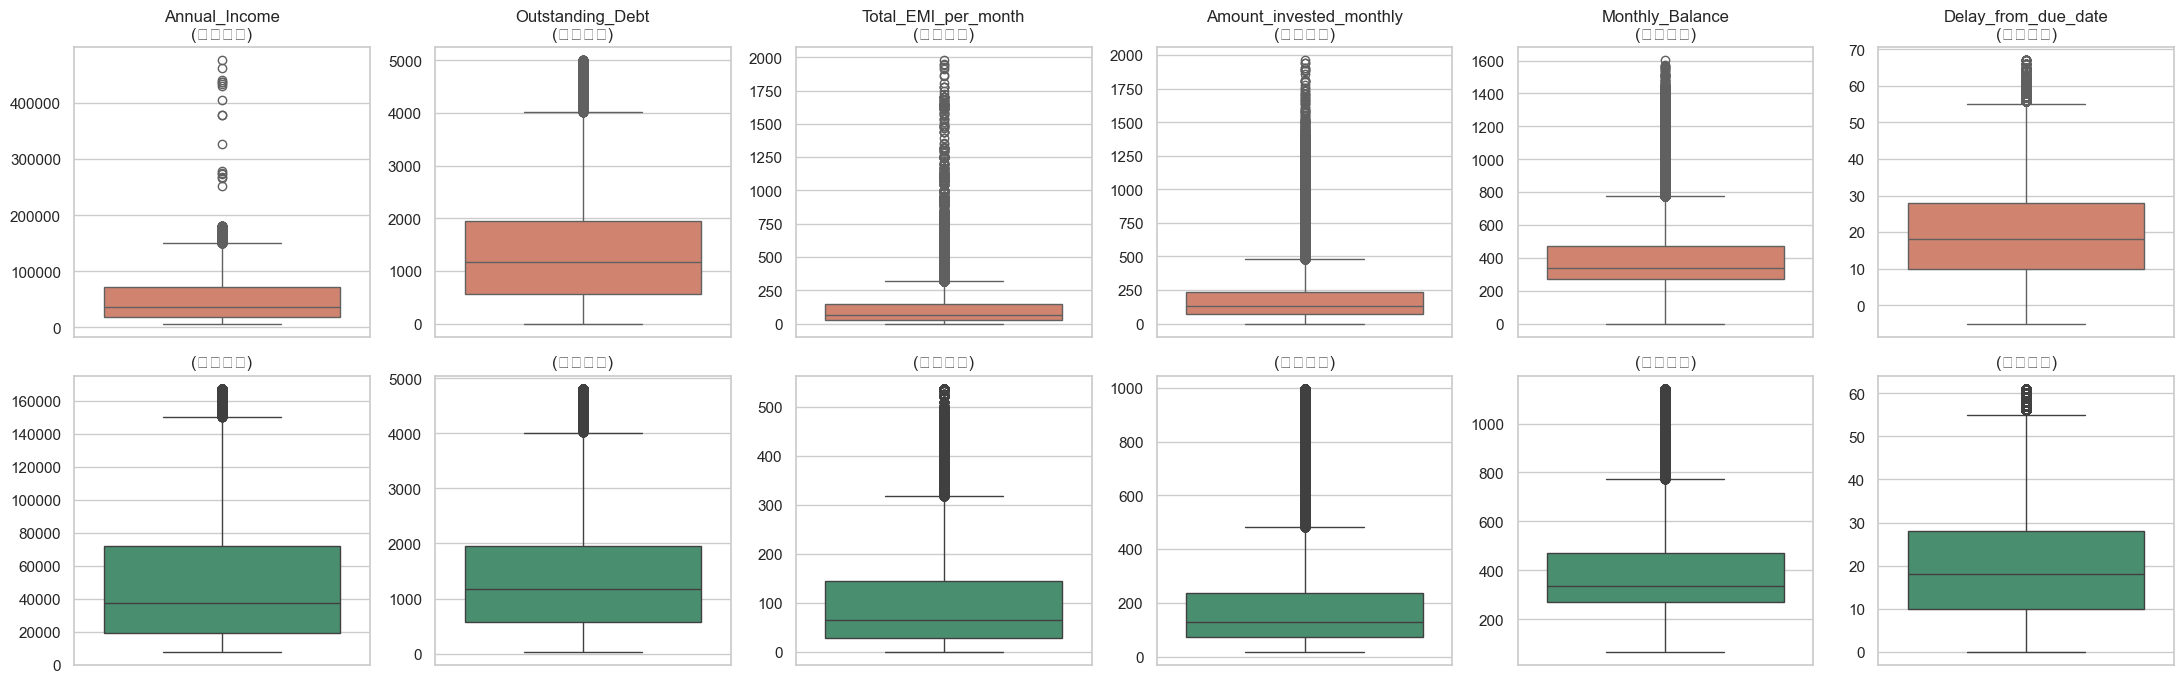

In [16]:
# ขอบล่าง/บนจาก train เท่านั้น
lower = X_train[NUM_COLS].quantile(0.01)
upper = X_train[NUM_COLS].quantile(0.99)

def winsorize(df):
    d = df.copy()
    d[NUM_COLS] = d[NUM_COLS].clip(lower=lower, upper=upper, axis=1)
    return d

X_train_w = winsorize(X_train)
X_valid_w = winsorize(X_valid)
test_w = winsorize(test_df[FEATURE_COLS])

# เทียบก่อน/หลัง
fig, axes = plt.subplots(2, 6, figsize=(22, 7))
for i, c in enumerate(["Annual_Income", "Outstanding_Debt", "Total_EMI_per_month",
                       "Amount_invested_monthly", "Monthly_Balance", "Delay_from_due_date"]):
    sns.boxplot(y=X_train[c], ax=axes[0, i], color="#e07a5f"); axes[0, i].set_title(f"{c}\n(ก่อน)")
    sns.boxplot(y=X_train_w[c], ax=axes[1, i], color="#3d9970"); axes[1, i].set_title("(หลัง)")
    for r in (0, 1): axes[r, i].set_ylabel("")
plt.tight_layout(); plt.show()

## Step 8 — ปรับสเกลตัวเลข + แปลงข้อมูลหมวดหมู่
สร้าง `ColumnTransformer` ที่ทำพร้อมกัน:
- **ตัวเลข → `RobustScaler`** (ใช้ median และ IQR จึงทนต่อ outlier ที่เหลือ)
- **`Credit_Mix` → Ordinal Encoding** (Bad=0, Standard=1, Good=2) เพราะมีลำดับ
- **`Occupation`, `Payment_Behaviour`, `Payment_of_Min_Amount` → One-Hot Encoding** เพราะไม่มีลำดับ (ถ้าใช้ Label Encoding โมเดลจะเข้าใจผิดว่ามีลำดับ)

`fit` กับ train เท่านั้น แล้ว `transform` กับ valid และ test

In [17]:
ONEHOT_COLS = ["Occupation", "Payment_Behaviour", "Payment_of_Min_Amount"]

preprocess = ColumnTransformer([
    ("num", RobustScaler(), NUM_COLS),
    ("mix", OrdinalEncoder(categories=[["Bad", "Standard", "Good"]]), ["Credit_Mix"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ONEHOT_COLS),
])

X_train_p = preprocess.fit_transform(X_train_w)
X_valid_p = preprocess.transform(X_valid_w)
X_test_p = preprocess.transform(test_w)
feature_names = preprocess.get_feature_names_out()

print("จำนวนฟีเจอร์หลัง scale + encode:", X_train_p.shape[1])
pd.DataFrame(X_train_p[:5], columns=feature_names).round(3)

จำนวนฟีเจอร์หลัง scale + encode: 45


,num__Age,num__Annual_Income,num__Monthly_Inhand_Salary,num__Num_Bank_Accounts,num__Num_Credit_Card,num__Interest_Rate,num__Num_of_Loan,num__Delay_from_due_date,num__Num_of_Delayed_Payment,num__Changed_Credit_Limit,num__Num_Credit_Inquiries,num__Outstanding_Debt,num__Credit_Utilization_Ratio,num__Total_EMI_per_month,num__Amount_invested_monthly,num__Monthly_Balance,num__Credit_History_Months,num__Num_Loan_Types,num__Prev_Outstanding_Debt,num__Prev_Delay_from_due_date,num__Prev_Credit_Utilization_Ratio,mix__Credit_Mix,cat__Occupation_Accountant,cat__Occupation_Architect,cat__Occupation_Developer,cat__Occupation_Doctor,cat__Occupation_Engineer,cat__Occupation_Entrepreneur,cat__Occupation_Journalist,cat__Occupation_Lawyer,cat__Occupation_Manager,cat__Occupation_Mechanic,cat__Occupation_Media_Manager,cat__Occupation_Musician,cat__Occupation_Scientist,cat__Occupation_Teacher,cat__Occupation_Writer,cat__Payment_Behaviour_High_spent_Large_value_payments,cat__Payment_Behaviour_High_spent_Medium_value_payments,cat__Payment_Behaviour_High_spent_Small_value_payments,cat__Payment_Behaviour_Low_spent_Large_value_payments,cat__Payment_Behaviour_Low_spent_Medium_value_payments,cat__Payment_Behaviour_Low_spent_Small_value_payments,cat__Payment_of_Min_Amount_No,cat__Payment_of_Min_Amount_Yes
0,-0.889,-0.122,-0.09,0.25,0.0,1.077,-0.333,2.389,1.222,-0.818,0.833,0.288,-0.674,-0.196,0.707,-0.417,-0.608,-0.5,0.288,2.389,-0.673,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-0.889,-0.122,-0.09,0.25,0.0,1.077,-0.333,2.389,1.000,-0.818,1.000,0.288,-0.338,-0.196,0.287,-0.126,-0.601,-0.5,0.288,2.389,-0.673,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.889,-0.122,-0.09,0.25,0.0,1.077,-0.333,2.389,1.222,-0.818,1.000,0.288,0.711,-0.196,-0.123,0.157,-0.595,-0.5,0.288,2.389,-0.338,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.889,-0.122,-0.09,0.25,0.0,1.077,-0.333,2.389,1.222,-0.818,1.000,0.288,0.066,-0.196,-0.253,0.411,-0.589,-0.5,0.288,2.389,0.712,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.889,-0.122,-0.09,0.25,0.0,1.077,-0.333,2.389,1.222,-0.713,1.000,0.288,0.005,-0.196,0.383,-0.154,-0.582,-0.5,0.288,2.389,0.066,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


## Step 9 — ลดมิติด้วย PCA
PCA แปลงฟีเจอร์เดิมเป็น "องค์ประกอบหลัก" ที่ไม่สัมพันธ์กัน เรียงตามปริมาณความแปรปรวนที่อธิบายได้ `n_components=0.98` หมายถึงเก็บจำนวนองค์ประกอบที่อธิบายข้อมูลได้ 98%

`fit` กับ train เท่านั้น

ฟีเจอร์ก่อน PCA: 45  ->  หลัง PCA: 35


/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/

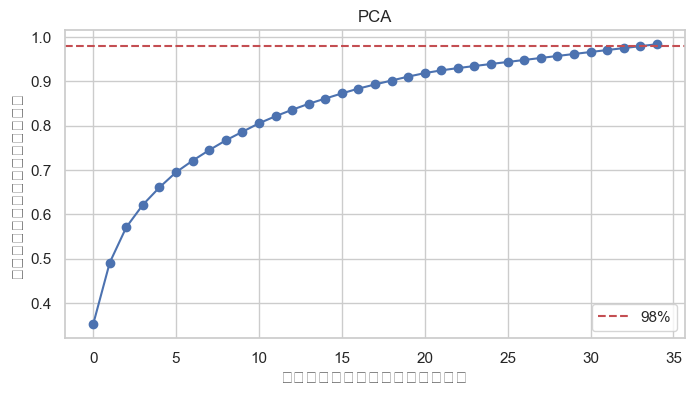

In [18]:
pca = PCA(n_components=0.98, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_p)
X_valid_pca = pca.transform(X_valid_p)
X_test_pca = pca.transform(X_test_p)

print(f"ฟีเจอร์ก่อน PCA: {X_train_p.shape[1]}  ->  หลัง PCA: {X_train_pca.shape[1]}")

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.98, color="r", ls="--", label="98%")
plt.xlabel("จำนวนองค์ประกอบ"); plt.ylabel("ความแปรปรวนสะสม"); plt.legend(); plt.title("PCA"); plt.show()

## Step 10 — ฟังก์ชันประเมินผล
คำนวณ accuracy ของ train และ valid, macro F1 (เฉลี่ย F1 ของทุกคลาสเท่าๆ กัน เหมาะเมื่อคลาสไม่สมดุล) และวาด Confusion Matrix

ถ้า train สูงกว่า valid มาก แปลว่าโมเดล **overfit**

In [19]:
# ถ้ายังไม่มีตัวแปร evals/fitted ให้สร้างใหม่ (แต่ถ้ามีผลของ 6 โมเดลแรกอยู่แล้วจะเก็บไว้ให้ครบ)
if "evals" not in globals():
    evals = {}
if "fitted" not in globals():
    fitted = {}

# เติมค่าเริ่มต้น is_pca=True ให้กับโมเดลเก่าที่รันไปแล้ว
for k in evals:
    evals[k].setdefault("is_pca", True)

def evaluate_classification(model, name, X_tr, X_va, y_tr, y_va, is_pca=True):
    pred_tr = model.predict(X_tr)
    pred_va = model.predict(X_va)
    evals[name] = {
        "train_acc": accuracy_score(y_tr, pred_tr),
        "valid_acc": accuracy_score(y_va, pred_va),
        "valid_macro_f1": f1_score(y_va, pred_va, average="macro"),
        "is_pca": is_pca,
    }
    fitted[name] = model
    print(f"{name}: train acc = {evals[name]['train_acc']:.4f} | valid acc = {evals[name]['valid_acc']:.4f} "
          f"| valid macro F1 = {evals[name]['valid_macro_f1']:.4f}")
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay.from_predictions(y_va, pred_va, display_labels=list(LABELS), ax=ax, colorbar=False)
    ax.grid(False); ax.set_title(name); plt.show()

## Step 11 — เทรนโมเดลและเทียบผล
ทุกโมเดลเทรนบนข้อมูลที่ผ่าน PCA แล้ว (`X_train_pca`)

### 11.1 Logistic Regression
โมเดลเชิงเส้น ประมาณความน่าจะเป็นของแต่ละคลาส (multinomial) เป็นโมเดลพื้นฐานที่เร็วและตีความง่าย

Logistic Regression: train acc = 0.6737 | valid acc = 0.6021 | valid macro F1 = 0.5778


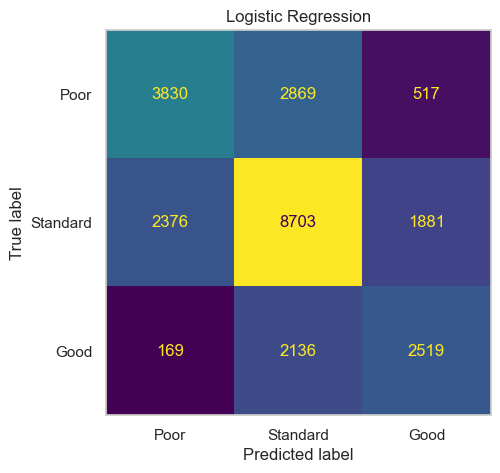

In [20]:
lr = LogisticRegression(max_iter=1000).fit(X_train_pca, y_train)
evaluate_classification(lr, "Logistic Regression", X_train_pca, X_valid_pca, y_train, y_valid)

### 11.2 K-Nearest Neighbors (k = 25)
ดูเพื่อนบ้านที่ใกล้ที่สุด 25 จุด แล้วโหวตคลาส (lazy learner: เทรนเร็ว ทำนายช้า)

KNN (k=25): train acc = 0.7657 | valid acc = 0.6560 | valid macro F1 = 0.6331


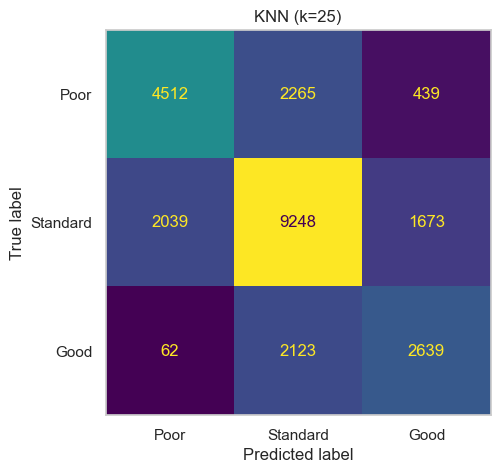

In [35]:
knn = KNeighborsClassifier(n_neighbors=25, n_jobs=-1).fit(X_train_pca, y_train)
evaluate_classification(knn, "KNN (k=25)", X_train_pca, X_valid_pca, y_train, y_valid)

### 11.3 Naive Bayes
ใช้ทฤษฎีบทของเบย์ โดยสมมติว่าฟีเจอร์เป็นอิสระต่อกัน (ซึ่ง PCA ช่วยให้ใกล้เคียงข้อสมมตินี้มากขึ้น)

Naive Bayes: train acc = 0.6616 | valid acc = 0.5810 | valid macro F1 = 0.5718


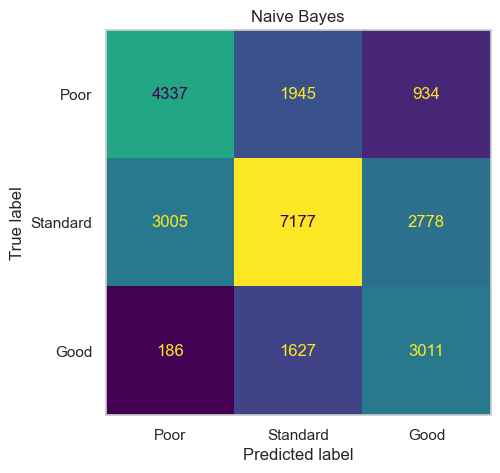

In [34]:
gnb = GaussianNB().fit(X_train_pca, y_train)
evaluate_classification(gnb, "Naive Bayes", X_train_pca, X_valid_pca, y_train, y_valid)

### 11.4 Decision Tree
ต้นไม้ถาม-ตอบ แบ่งข้อมูลทีละเงื่อนไข จำกัด `max_depth=8` เพื่อลด overfit (ถ้าไม่จำกัด ต้นไม้จะจำ train ได้เกือบ 100%)

Decision Tree: train acc = 0.7193 | valid acc = 0.6193 | valid macro F1 = 0.5871


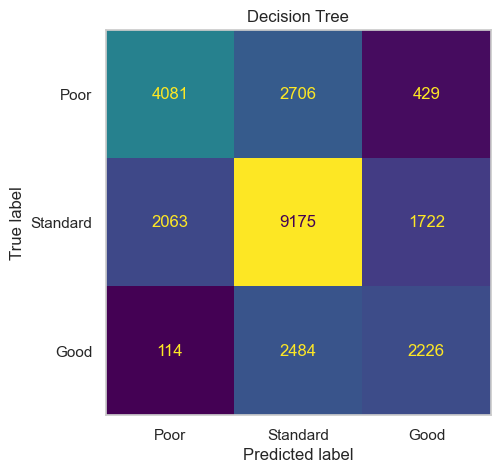

In [36]:
dt = DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE).fit(X_train_pca, y_train)
evaluate_classification(dt, "Decision Tree", X_train_pca, X_valid_pca, y_train, y_valid)

### 11.5 Random Forest
รวมต้นไม้หลายร้อยต้น (bagging) แล้วโหวต ลด overfit ได้ดีกว่าต้นไม้ต้นเดียว

Random Forest: train acc = 0.9617 | valid acc = 0.6972 | valid macro F1 = 0.6829


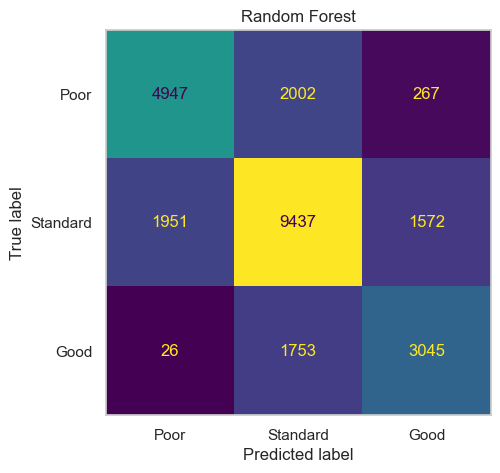

In [37]:
rf = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=2,
                            n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_pca, y_train)
evaluate_classification(rf, "Random Forest", X_train_pca, X_valid_pca, y_train, y_valid)

### 11.6 Neural Network (MLP)
โครงข่ายประสาทเทียมหลายชั้น (64-128-64) ใช้ `early_stopping` หยุดเมื่อ valid ไม่ดีขึ้นเพื่อลด overfit
(ใช้ `MLPClassifier` ของ scikit-learn จึงไม่ต้องติดตั้ง TensorFlow)

Neural Network (MLP): train acc = 0.8689 | valid acc = 0.6950 | valid macro F1 = 0.6849


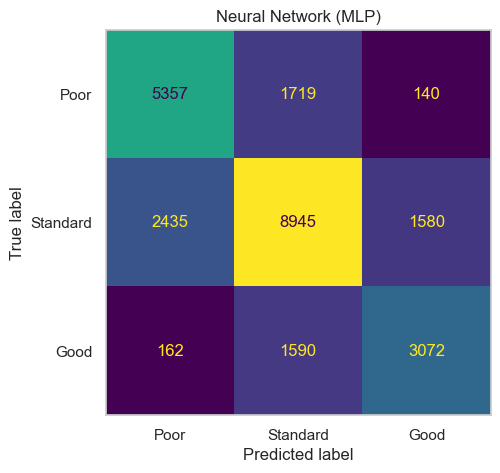

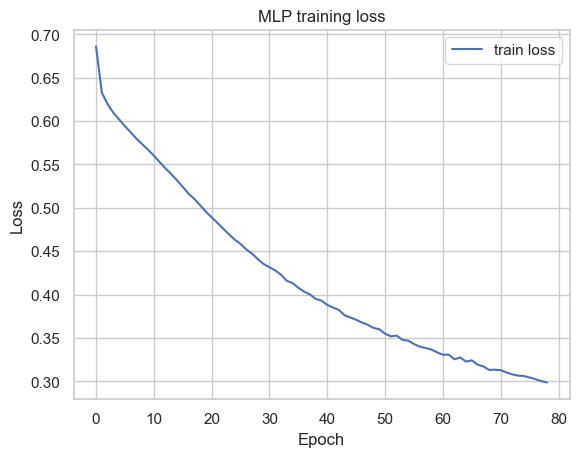

In [38]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 128, 64), early_stopping=True,
                    max_iter=300, random_state=RANDOM_STATE).fit(X_train_pca, y_train)
evaluate_classification(mlp, "Neural Network (MLP)", X_train_pca, X_valid_pca, y_train, y_valid)

plt.plot(mlp.loss_curve_, label="train loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(True); plt.title("MLP training loss"); plt.show()

Random Forest (No PCA): train acc = 0.7930 | valid acc = 0.6625 | valid macro F1 = 0.6562


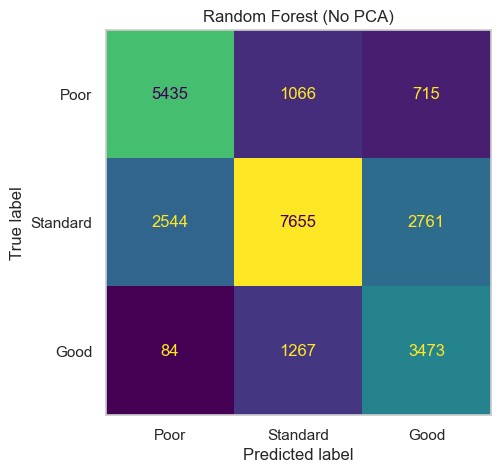

HistGradientBoosting (No PCA): train acc = 0.8091 | valid acc = 0.6751 | valid macro F1 = 0.6710


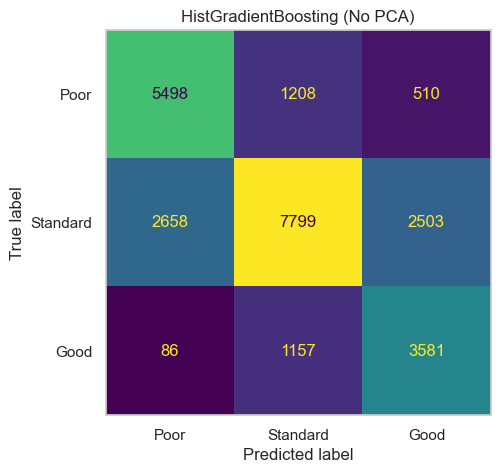

In [26]:
from sklearn.ensemble import HistGradientBoostingClassifier

# --- 1. ปรับข้อมูล Step 7-8 ให้ตรงกับ y_train (75,000 แถว) อัตโนมัติ ---
if len(X_train_p) != len(y_train):
    lower = X_train[NUM_COLS].quantile(0.01)
    upper = X_train[NUM_COLS].quantile(0.99)
    def winsorize(df):
        d = df.copy()
        d[NUM_COLS] = d[NUM_COLS].clip(lower=lower, upper=upper, axis=1)
        return d

    X_train_w = winsorize(X_train)
    X_valid_w = winsorize(X_valid)
    test_w = winsorize(test_df[FEATURE_COLS])

    X_train_p = preprocess.fit_transform(X_train_w)
    X_valid_p = preprocess.transform(X_valid_w)
    X_test_p = preprocess.transform(test_w)

    X_train_pca = pca.fit_transform(X_train_p)
    X_valid_pca = pca.transform(X_valid_p)
    X_test_pca = pca.transform(X_test_p)
    print(f"อัปเดตขนาดข้อมูลสำเร็จ: X_train_p = {X_train_p.shape}, y_train = {y_train.shape}")

# --- 2. เทรน Random Forest (ไม่ผ่าน PCA) ---
rf_raw = RandomForestClassifier(
    n_estimators=250,
    max_depth=16,
    min_samples_leaf=4,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE
).fit(X_train_p, y_train)
evaluate_classification(rf_raw, "Random Forest (No PCA)", X_train_p, X_valid_p, y_train, y_valid, is_pca=False)

# --- 3. เทรน HistGradientBoosting (ไม่ผ่าน PCA) ---
hgb = HistGradientBoostingClassifier(
    max_iter=350,
    max_depth=7,
    learning_rate=0.05,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=RANDOM_STATE
).fit(X_train_p, y_train)
evaluate_classification(hgb, "HistGradientBoosting (No PCA)", X_train_p, X_valid_p, y_train, y_valid, is_pca=False)

## Step 12 — เปรียบเทียบทุกโมเดล

,train_acc,valid_acc,valid_macro_f1,is_pca
Neural Network (MLP),0.868933,0.69496,0.684908,True
Random Forest,0.961747,0.69716,0.682913,True
HistGradientBoosting (No PCA),0.80912,0.67512,0.671046,False
Random Forest (No PCA),0.792987,0.66252,0.656196,False
KNN (k=25),0.765693,0.65596,0.633071,True
Decision Tree,0.719347,0.61928,0.587055,True
Logistic Regression,0.67372,0.60208,0.577832,True
Naive Bayes,0.661573,0.581,0.571751,True


/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2682864923.py:6: UserWarning: Glyph 3594 (\N{THAI CHARACTER CHO CHANG}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2682864923.py:6: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2682864923.py:6: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2682864923.py:6: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2682864923.py:6: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nq

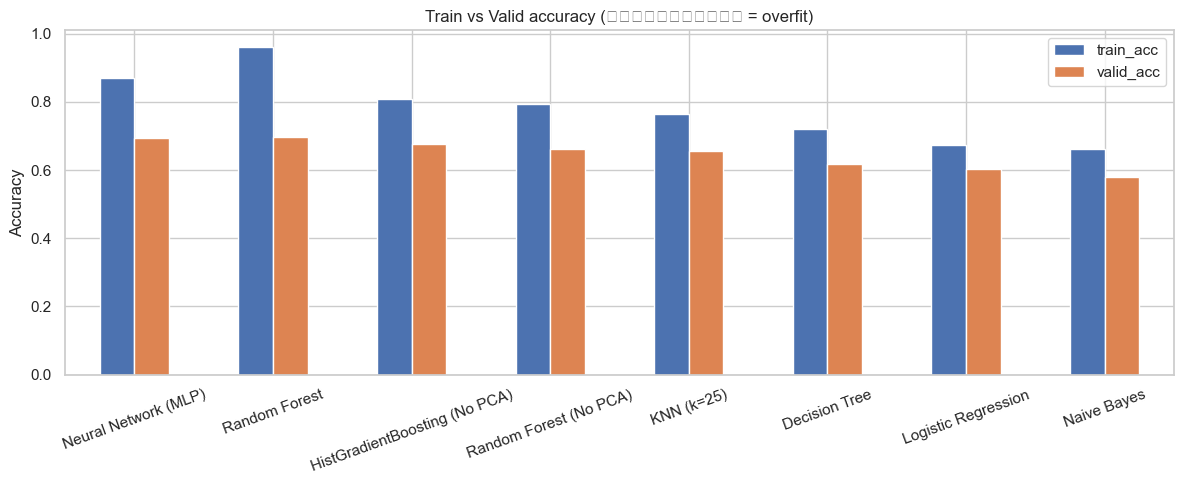

โมเดลที่ดีที่สุด (macro F1): Neural Network (MLP)


In [27]:
results = pd.DataFrame(evals).T.round(4).sort_values("valid_macro_f1", ascending=False)
display(results)

ax = results[["train_acc", "valid_acc"]].plot(kind="bar", figsize=(12, 5), rot=20)
ax.set_ylabel("Accuracy"); ax.set_title("Train vs Valid accuracy (ช่องว่างมาก = overfit)")
plt.tight_layout(); plt.show()

best_name = results.index[0]
print("โมเดลที่ดีที่สุด (macro F1):", best_name)

In [28]:
best_model = fitted[best_name]
print(classification_report(y_valid, best_model.predict(X_valid_pca), target_names=list(LABELS)))

              precision    recall  f1-score   support

        Poor       0.67      0.74      0.71      7216
    Standard       0.73      0.69      0.71     12960
        Good       0.64      0.64      0.64      4824

    accuracy                           0.69     25000
   macro avg       0.68      0.69      0.68     25000
weighted avg       0.70      0.69      0.69     25000



## Step 13 — ฟีเจอร์ไหนสำคัญที่สุด
PCA ทำให้ฟีเจอร์เดิมถูกผสมกัน จึงดู feature importance ตรงๆ ไม่ได้ ที่นี่เทรน Random Forest แยกอีกตัวบนฟีเจอร์ **ก่อน PCA** (`X_train_p`) เพื่อดูว่าตัวแปรจริงตัวไหนมีผลต่อเครดิตสกอร์มากสุด (ใช้เพื่อทำความเข้าใจเท่านั้น ไม่ได้ใช้ทำนาย)

valid acc (ก่อน PCA): 0.7169


/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2303798751.py:7: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2303798751.py:7: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2303798751.py:7: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/var/folders/31/9k1nqy5s707g8pz9zy6gwnyr0000gn/T/ipykernel_91788/2303798751.py:7: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/pytho

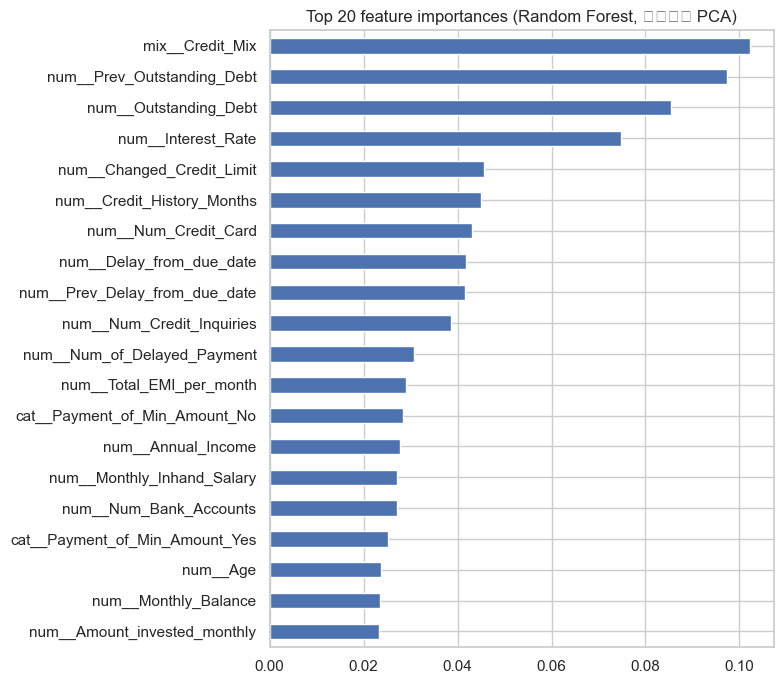

In [ ]:
rf_interp = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=2,
                                   n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_p, y_train)
print("valid acc (ก่อน PCA):", round(accuracy_score(y_valid, rf_interp.predict(X_valid_p)), 4))

imp = pd.Series(rf_interp.feature_importances_, index=feature_names).sort_values().tail(20)
imp.plot(kind="barh", figsize=(8, 7), title="Top 20 feature importances (Random Forest, ก่อน PCA)")
plt.tight_layout(); plt.show()

## Step 14 — ทำนายเครดิตสกอร์ของ `test.csv`
ใช้โมเดลที่ดีที่สุดทำนาย แล้วบันทึกเป็น `test_predictions.csv`
(`test.csv` ไม่มีเฉลย จึงวัด accuracy บนไฟล์นี้ไม่ได้ ใช้คะแนน valid จาก Step 12 เป็นตัวอ้างอิง)

In [ ]:
inv = {v: k for k, v in LABELS.items()}
pred_test = best_model.predict(X_test_pca)

submission = test_df[["ID", "Customer_ID", "Month"]].copy()
submission["Predicted_Credit_Score"] = pd.Series(pred_test).map(inv).values
submission.to_csv("test_predictions.csv", index=False)

print(submission["Predicted_Credit_Score"].value_counts(normalize=True).round(3).to_string())
submission.head(10)

Predicted_Credit_Score
Standard    0.487
Poor        0.316
Good        0.198


,ID,Customer_ID,Month,Predicted_Credit_Score
0,0x16292,CUS_0x1000,September,Poor
1,0x16293,CUS_0x1000,October,Poor
2,0x16294,CUS_0x1000,November,Poor
3,0x16295,CUS_0x1000,December,Poor
4,0x66aa,CUS_0x1009,September,Standard
5,0x66ab,CUS_0x1009,October,Standard
6,0x66ac,CUS_0x1009,November,Standard
7,0x66ad,CUS_0x1009,December,Good
8,0x1efe,CUS_0x100b,September,Standard
9,0x1eff,CUS_0x100b,October,Standard


## สรุปและแนวทางต่อยอด
- เทียบผลจากตารางใน Step 12 โดยดูทั้ง valid accuracy และ macro F1
- ช่องว่างระหว่าง train กับ valid มาก = overfit ลอง `max_depth`/`min_samples_leaf` ที่เล็กลง
- ต่อยอด: จูนไฮเปอร์พารามิเตอร์ด้วย `GridSearchCV` / `RandomizedSearchCV`, ลองถ่วงน้ำหนักคลาส (`class_weight="balanced"`), หรือเพิ่มฟีเจอร์ เช่น จำนวนประเภทสินเชื่อจาก `Type_of_Loan`